<a href="https://colab.research.google.com/github/MuhammadAryatamaM/244107020028-mobile-course/blob/main/T10_244107020028_Muhammad_Aryatama_M.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/MuhammadAryatamaM/Machine-Learning/blob/main/T10_244107020028_Muhammad_Aryatama_M.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 14

# Praktikum 1: Klasifikasi Cat vs. Dog

## Langkah 1 - Import Library

In [3]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

## Langkah 2 - Pra Pengolahan Data

In [9]:
!unzip dataset.zip

Streaming output truncated to the last 5000 lines.
  inflating: dataset/training_set/cats/cat.2059.jpg  
  inflating: __MACOSX/dataset/training_set/cats/._cat.2059.jpg  
  inflating: dataset/training_set/cats/cat.1550.jpg  
  inflating: __MACOSX/dataset/training_set/cats/._cat.1550.jpg  
  inflating: dataset/training_set/cats/cat.746.jpg  
  inflating: __MACOSX/dataset/training_set/cats/._cat.746.jpg  
  inflating: dataset/training_set/cats/cat.9.jpg  
  inflating: __MACOSX/dataset/training_set/cats/._cat.9.jpg  
  inflating: dataset/training_set/cats/cat.2918.jpg  
  inflating: __MACOSX/dataset/training_set/cats/._cat.2918.jpg  
  inflating: dataset/training_set/cats/cat.752.jpg  
  inflating: __MACOSX/dataset/training_set/cats/._cat.752.jpg  
  inflating: dataset/training_set/cats/cat.3390.jpg  
  inflating: __MACOSX/dataset/training_set/cats/._cat.3390.jpg  
  inflating: dataset/training_set/cats/cat.1587.jpg  
  inflating: __MACOSX/dataset/training_set/cats/._cat.1587.jpg  
  infla

In [10]:
# Preprocessing data training
train_datagen = ImageDataGenerator(rescale = 1./255,
                                   shear_range = 0.2,
                                   zoom_range = 0.2,
                                   horizontal_flip = True)
training_set = train_datagen.flow_from_directory('dataset/training_set',
                                                 target_size = (64, 64),
                                                 batch_size = 32,
                                                 class_mode = 'binary')
# Preprocessing data testing
test_datagen = ImageDataGenerator(rescale = 1./255)
test_set = test_datagen.flow_from_directory('dataset/test_set',
                                            target_size = (64, 64),
                                            batch_size = 32,
                                            class_mode = 'binary')

Found 8000 images belonging to 2 classes.
Found 2000 images belonging to 2 classes.


## Langkah 3 - Pembuatan Model CNN

In [12]:
# inisialisasi model cnn
cnn = tf.keras.models.Sequential()

# layer konvolusi 1
cnn.add(tf.keras.layers.Conv2D(filters=32, kernel_size=3, activation='relu', input_shape=[64, 64, 3]))

# layer pooling 1
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2, strides=2))

# layer konvolusi & pooling 2
cnn.add(tf.keras.layers.Conv2D(filters=32, kernel_size=3, activation='relu'))
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2, strides=2))

cnn.add(tf.keras.layers.Flatten())

# fully connnected layer 1 (input)
cnn.add(tf.keras.layers.Dense(units=128, activation='relu'))

# fully connnected layer 2 (output)
cnn.add(tf.keras.layers.Dense(units=1, activation='sigmoid'))

# compile model cnn
cnn.compile(optimizer = 'adam', loss = 'binary_crossentropy', metrics = ['accuracy'])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


## Langkah 4 - Fit CNN

In [13]:
cnn.fit(x = training_set, validation_data = test_set, epochs = 25)

Epoch 1/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 77s 304ms/step - accuracy: 0.5551 - loss: 0.6850 - val_accuracy: 0.6475 - val_loss: 0.6489
Epoch 2/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 79s 293ms/step - accuracy: 0.6557 - loss: 0.6241 - val_accuracy: 0.6825 - val_loss: 0.5998
Epoch 3/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 78s 312ms/step - accuracy: 0.7013 - loss: 0.5722 - val_accuracy: 0.7085 - val_loss: 0.5636
Epoch 4/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 73s 292ms/step - accuracy: 0.7268 - loss: 0.5409 - val_accuracy: 0.7190 - val_loss: 0.5675
Epoch 5/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 73s 290ms/step - accuracy: 0.7424 - loss: 0.5197 - val_accuracy: 0.7225 - val_loss: 0.5531
Epoch 6/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 85s 303ms/step - accuracy: 0.7564 - loss: 0.4940 - val_accuracy: 0.7415 - val_loss: 0.5310
Epoch 7/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 74s 294ms/step - accuracy: 0.7729 - loss: 0.4690 - val_accuracy: 0.7565 - val_loss: 0.5110
Epoch 8/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 73s 291ms/step - accuracy: 0.7904 - loss: 0

## Langkah 5 - Prediksi dengan 1 Citra

In [14]:
import numpy as np
from tensorflow.keras.preprocessing import image

test_image = image.load_img('dataset/single_prediction/cat_or_dog_1.jpg', target_size = (64, 64))
test_image = image.img_to_array(test_image)
test_image = np.expand_dims(test_image, axis = 0)
result = cnn.predict(test_image)
training_set.class_indices

if result[0][0] == 1:
    prediction = 'dog'
else:
    prediction = 'cat'

print(prediction)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 190ms/step
dog


# Praktikum 2: Klasifikasi Multilabel dengan dataset CIFAR

## Langkah 1 - Load Library

In [15]:
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt

## Langkah 2 - Unduh Dataset CIFAR

In [16]:
(train_images, train_labels), (test_images, test_labels) = datasets.cifar10.load_data()

# Normalize pixel values to be between 0 and 1
train_images, test_images = train_images / 255.0, test_images / 255.0

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 19s 0us/step


## Langkah 3 - Verifikasi Data

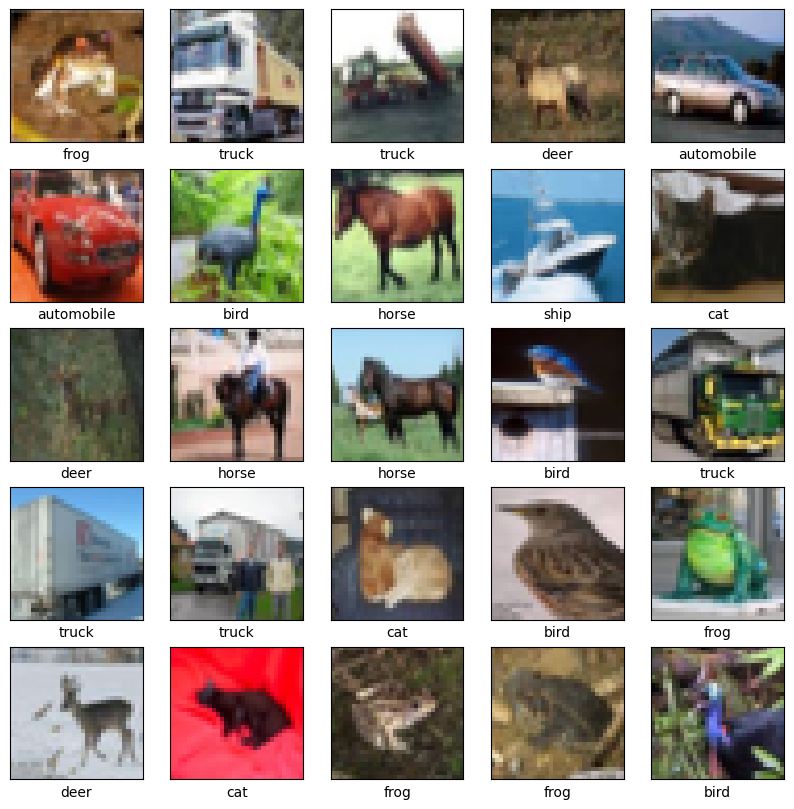

In [17]:
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

plt.figure(figsize=(10,10))
for i in range(25):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i])
    # The CIFAR labels happen to be arrays,
    # which is why you need the extra index
    plt.xlabel(class_names[train_labels[i][0]])
plt.show()

## Langkah 4 - Buat Model CNN

In [18]:
# layer konvolusi
model = models.Sequential()
model.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(64, (3, 3), activation='relu'))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(64, (3, 3), activation='relu'))

# cek arsitektur konvolusi
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 4, 4, 64)       │        36,928 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 56,320 (220.00 KB)

 Trainable params: 56,320 (220.00 KB)

 Non-trainable params: 0 (0.00 B)

In [19]:
# tambah layer fully connected
model.add(layers.Flatten())
model.add(layers.Dense(64, activation='relu'))
model.add(layers.Dense(10))

# cek arsitektur model ccnn
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 4, 4, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 122,570 (478.79 KB)

 Trainable params: 122,570 (478.79 KB)

 Non-trainable params: 0 (0.00 B)

In [20]:
# compile model cnn
model.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

## Langkah 5 - Fit Model

In [21]:
history = model.fit(train_images, train_labels, epochs=10,
                    validation_data=(test_images, test_labels))

Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 106s 67ms/step - accuracy: 0.4312 - loss: 1.5526 - val_accuracy: 0.5408 - val_loss: 1.2795
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 140s 65ms/step - accuracy: 0.5750 - loss: 1.1973 - val_accuracy: 0.6067 - val_loss: 1.1071
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 143s 66ms/step - accuracy: 0.6250 - loss: 1.0567 - val_accuracy: 0.6478 - val_loss: 1.0062
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 108s 69ms/step - accuracy: 0.6611 - loss: 0.9688 - val_accuracy: 0.6506 - val_loss: 0.9977
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 114s 73ms/step - accuracy: 0.6835 - loss: 0.8995 - val_accuracy: 0.6723 - val_loss: 0.9607
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 110s 70ms/step - accuracy: 0.7025 - loss: 0.8429 - val_accuracy: 0.6873 - val_loss: 0.8936
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 104s 66ms/step - accuracy: 0.7221 - loss: 0.7955 - val_accuracy: 0.6944 - val_loss: 0.8855
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 102s 65ms/step - accuracy: 

## Langkah 6 - Evaluasi Model

313/313 - 6s - 20ms/step - accuracy: 0.6973 - loss: 0.8819
0.6973000168800354


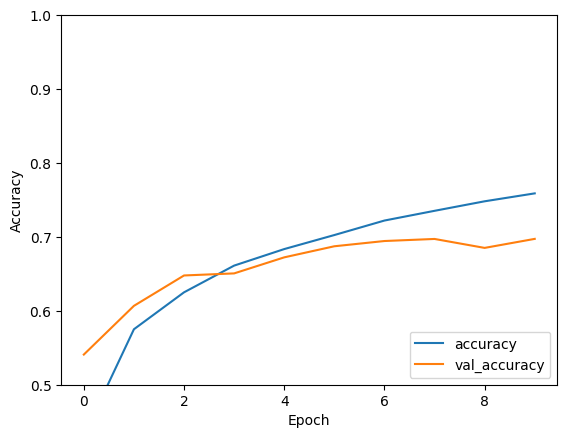

In [22]:
plt.plot(history.history['accuracy'], label='accuracy')
plt.plot(history.history['val_accuracy'], label = 'val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0.5, 1])
plt.legend(loc='lower right')

test_loss, test_acc = model.evaluate(test_images, test_labels, verbose=2)

print(test_acc)

# Tugas Praktikum
1. Modifikasi model CNN pada praktikum 2 sehingga didapatkan akurasi testing lebih dari 80%.
2. Buatlah model CNN untuk klasifikasi dataset MNIST.

## 1. Modifikasi Model CNN CIFAR-10 (Akurasi Testing > 80%)
- Menambah kedalaman filter konvolusi secara bertahap (32 -> 64 -> 128) dengan padding `'same'`.
- Menambahkan Batch Normalization tiap blok konvolusi dan dense layer untuk mempercepat konvergensi dan menstabilkan pelatihan.
- Menambahkan Dropout untuk mencegah overfitting.
- Melatih model dengan jumlah epoch yang cukup (misal 25).

In [4]:
from tensorflow.keras import datasets, layers, models
from tensorflow.keras.optimizers import Adam

# load dan normalisasi dataset CIFAR-10
(train_images, train_labels), (test_images, test_labels) = datasets.cifar10.load_data()
train_images, test_images = train_images / 255.0, test_images / 255.0

# model cnn yang dimodifikasi
model_mod = models.Sequential([
    # Blok 1
    layers.Conv2D(32, (3, 3), padding='same', activation='relu', input_shape=(32, 32, 3)),
    layers.BatchNormalization(),
    layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.2),

    # Blok 2
    layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.3),

    # Blok 3
    layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.4),

    # Fully Connected
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    layers.Dense(10)
])

# compile model
model_mod.compile(optimizer=Adam(learning_rate=0.001),
                  loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
                  metrics=['accuracy'])

model_mod.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 552,874 (2.11 MB)

 Trainable params: 551,722 (2.10 MB)

 Non-trainable params: 1,152 (4.50 KB)

In [5]:
# train model modifikasi
history_mod = model_mod.fit(train_images, train_labels, epochs=25, batch_size=64,
                            validation_data=(test_images, test_labels))

# evaluasi & print akurasi
test_loss_mod, test_acc_mod = model_mod.evaluate(test_images, test_labels, verbose=2)
print(f"\nAkurasi Testing Model Modifikasi: {test_acc_mod * 100:.2f}%")

Epoch 1/25
782/782 ━━━━━━━━━━━━━━━━━━━━ 55s 40ms/step - accuracy: 0.4473 - loss: 1.6020 - val_accuracy: 0.5676 - val_loss: 1.1973
Epoch 2/25
782/782 ━━━━━━━━━━━━━━━━━━━━ 38s 9ms/step - accuracy: 0.6324 - loss: 1.0434 - val_accuracy: 0.6886 - val_loss: 0.8702
Epoch 3/25
782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.6972 - loss: 0.8709 - val_accuracy: 0.6925 - val_loss: 0.9048
Epoch 4/25
782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.7318 - loss: 0.7720 - val_accuracy: 0.7650 - val_loss: 0.6759
Epoch 5/25
782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.7559 - loss: 0.7061 - val_accuracy: 0.7674 - val_loss: 0.6575
Epoch 6/25
782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.7784 - loss: 0.6442 - val_accuracy: 0.7685 - val_loss: 0.6626
Epoch 7/25
782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.7893 - loss: 0.6088 - val_accuracy: 0.8048 - val_loss: 0.5750
Epoch 8/25
782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.8086 - loss: 0.5591 - val_accuracy:

## 2. Model CNN untuk Klasifikasi Dataset MNIST
Membangun dan mengevaluasi arsitektur CNN untuk klasifikasi 10 kelas digit pada dataset MNIST.

In [6]:
# load dataset MNIST
(X_train_m, y_train_m), (X_test_m, y_test_m) = datasets.mnist.load_data()

# normalisasi pixel
X_train_m = X_train_m / 255.0
X_test_m = X_test_m / 255.0

# reshape citra agar memiliki dimensi channel (28, 28, 1)
X_train_m = X_train_m.reshape((-1, 28, 28, 1))
X_test_m = X_test_m.reshape((-1, 28, 28, 1))

# model CNN untuk MNIST
model_mnist = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10)
])

# compile model
model_mnist.compile(optimizer='adam',
                    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
                    metrics=['accuracy'])

model_mnist.summary()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_12 (Conv2D)              │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
# train model CNN pada MNIST
history_mnist = model_mnist.fit(X_train_m, y_train_m, epochs=5, batch_size=64,
                                validation_data=(X_test_m, y_test_m))

# evaluasi model
test_loss_mnist, test_acc_mnist = model_mnist.evaluate(X_test_m, y_test_m, verbose=2)
print(f"\nAkurasi Testing Model CNN pada MNIST: {test_acc_mnist * 100:.2f}%")

Epoch 1/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 16s 13ms/step - accuracy: 0.9424 - loss: 0.1889 - val_accuracy: 0.9845 - val_loss: 0.0525
Epoch 2/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9819 - loss: 0.0576 - val_accuracy: 0.9850 - val_loss: 0.0441
Epoch 3/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9875 - loss: 0.0400 - val_accuracy: 0.9846 - val_loss: 0.0475
Epoch 4/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9904 - loss: 0.0308 - val_accuracy: 0.9880 - val_loss: 0.0353
Epoch 5/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9924 - loss: 0.0249 - val_accuracy: 0.9883 - val_loss: 0.0333
313/313 - 3s - 11ms/step - accuracy: 0.9883 - loss: 0.0333

Akurasi Testing Model CNN pada MNIST: 98.83%
